# LAB 4 - Random Forest Classification

Classify the diabetes dataset (`Class`: 0 = non-diabetic, 1 = diabetic) with a
**Random Forest**, then study how the model behaves when we change two hyper-parameters:

1. **Tree height** - `max_depth`
2. **Number of trees** - `n_estimators`

For every setting we record **Accuracy, Precision and Recall** on the test set and plot the results.

## 1. Import libraries and load the data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, classification_report

df = pd.read_csv("LAB1_cleaned_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (768, 9)


,Pregnant,Glucose,Diastolic_BP,Skin_Fold,Serum_Insulin,BMI,Diabetes_Pedigree,Age,Class
0,6,148.0,72.0,35.0,125.0,33.6,0.627,50,1
1,1,85.0,66.0,29.0,125.0,26.6,0.351,31,0
2,8,183.0,64.0,29.0,125.0,23.3,0.672,32,1
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21,0
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33,1


## 2. Split into features (X) and target (y), then train / test sets

In [2]:
X = df.drop(columns="Class")
y = df["Class"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)
print("Train class balance:", dict(y_train.value_counts()))
print("Test  class balance:", dict(y_test.value_counts()))

Train: (576, 8)  Test: (192, 8)
Train class balance: {0: np.int64(375), 1: np.int64(201)}
Test  class balance: {0: np.int64(125), 1: np.int64(67)}


## 3. Baseline Random Forest

A default forest first, so later results have something to compare against.

In [3]:
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)
y_pred = rf.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall   :", round(recall_score(y_test, y_pred), 3))
print("\nConfusion matrix:\n", confusion_matrix(y_test, y_pred))
print("\nClassification report:\n", classification_report(y_test, y_pred))

Accuracy : 0.74
Precision: 0.649
Recall   : 0.552

Confusion matrix:
 [[105  20]
 [ 30  37]]

Classification report:
               precision    recall  f1-score   support

           0       0.78      0.84      0.81       125
           1       0.65      0.55      0.60        67

    accuracy                           0.74       192
   macro avg       0.71      0.70      0.70       192
weighted avg       0.73      0.74      0.73       192



## 4. Experiment 1 - varying tree height (`max_depth`)

Keep the number of trees fixed at 100 and increase the maximum depth from 1 to 15.
Shallow trees underfit; very deep trees can overfit.

In [4]:
depths = list(range(1, 16))
rows = []

for d in depths:
    m = RandomForestClassifier(n_estimators=100, max_depth=d, random_state=42)
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({
        "max_depth":  d,
        "Accuracy":   accuracy_score(y_test, p),
        "Precision":  precision_score(y_test, p),
        "Recall":     recall_score(y_test, p),
    })

depth_results = pd.DataFrame(rows)
depth_results.round(3)

,max_depth,Accuracy,Precision,Recall
0,1,0.714,0.875,0.209
1,2,0.729,0.703,0.388
2,3,0.734,0.682,0.448
3,4,0.729,0.660,0.463
4,5,0.734,0.654,0.507
5,6,0.750,0.679,0.537
6,7,0.734,0.660,0.493
7,8,0.734,0.643,0.537
8,9,0.750,0.673,0.552
9,10,0.750,0.656,0.597


### 4.1 Graph - metrics vs tree height

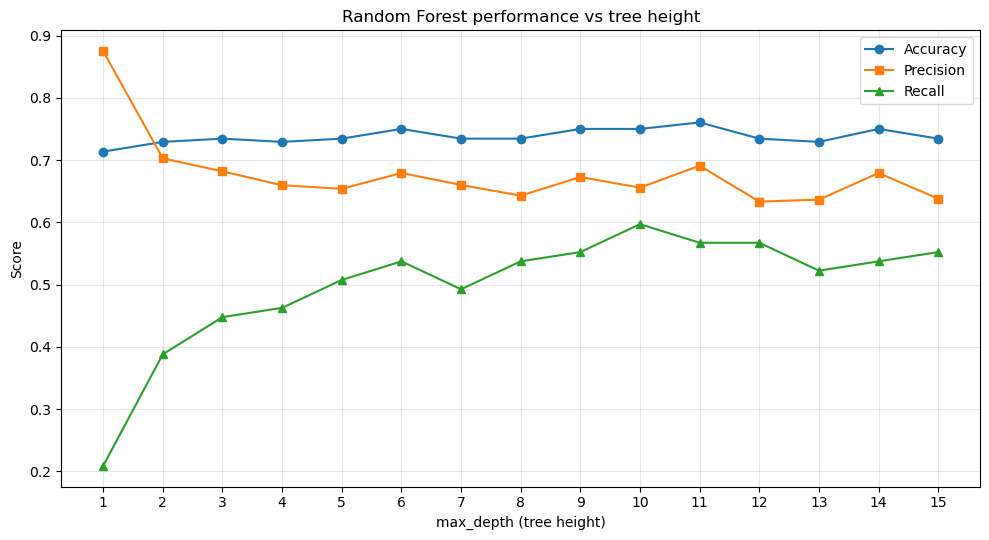

In [5]:
plt.figure(figsize=(10, 5.5))
plt.plot(depth_results["max_depth"], depth_results["Accuracy"],  marker="o", label="Accuracy")
plt.plot(depth_results["max_depth"], depth_results["Precision"], marker="s", label="Precision")
plt.plot(depth_results["max_depth"], depth_results["Recall"],    marker="^", label="Recall")
plt.xlabel("max_depth (tree height)")
plt.ylabel("Score")
plt.title("Random Forest performance vs tree height")
plt.xticks(depths)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Experiment 2 - varying the number of trees (`n_estimators`)

Now fix the depth and grow the forest from 10 up to 300 trees.

In [6]:
best_depth = int(depth_results.loc[depth_results["Accuracy"].idxmax(), "max_depth"])
print("Using best depth from Experiment 1:", best_depth)

n_trees = [10, 25, 50, 100, 150, 200, 300]
rows = []

for n in n_trees:
    m = RandomForestClassifier(n_estimators=n, max_depth=best_depth, random_state=42)
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    rows.append({
        "n_estimators": n,
        "Accuracy":     accuracy_score(y_test, p),
        "Precision":    precision_score(y_test, p),
        "Recall":       recall_score(y_test, p),
    })

tree_results = pd.DataFrame(rows)
tree_results.round(3)

Using best depth from Experiment 1: 11


,n_estimators,Accuracy,Precision,Recall
0,10,0.729,0.642,0.507
1,25,0.750,0.673,0.552
2,50,0.724,0.625,0.522
3,100,0.760,0.691,0.567
4,150,0.755,0.679,0.567
5,200,0.750,0.673,0.552
6,300,0.734,0.643,0.537


### 5.1 Graph - metrics vs number of trees

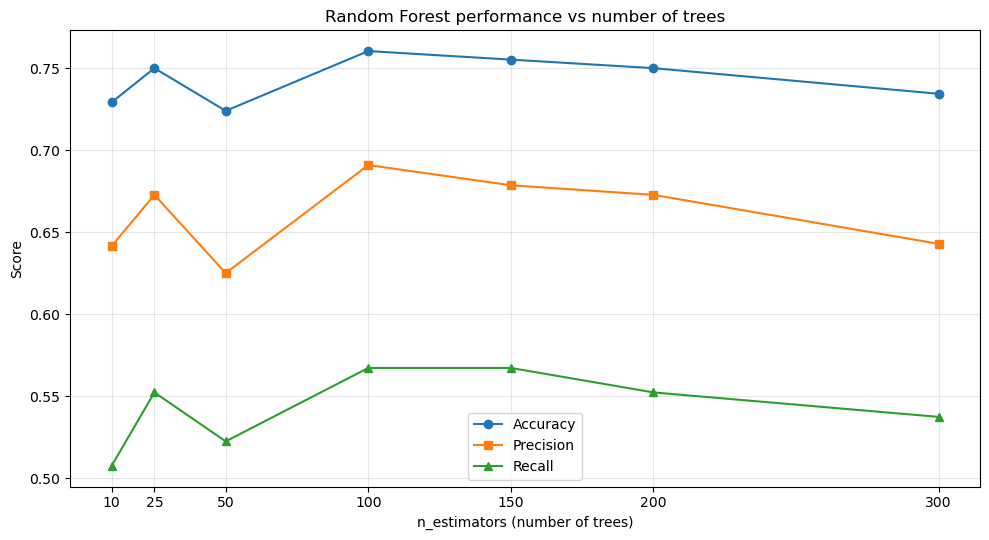

In [7]:
plt.figure(figsize=(10, 5.5))
plt.plot(tree_results["n_estimators"], tree_results["Accuracy"],  marker="o", label="Accuracy")
plt.plot(tree_results["n_estimators"], tree_results["Precision"], marker="s", label="Precision")
plt.plot(tree_results["n_estimators"], tree_results["Recall"],    marker="^", label="Recall")
plt.xlabel("n_estimators (number of trees)")
plt.ylabel("Score")
plt.title("Random Forest performance vs number of trees")
plt.xticks(n_trees)
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 6. Bar-chart comparison of the best model

Pick the best (depth, n_estimators) combination found above and show its three metrics
side by side.

Best model -> max_depth=11, n_estimators=100
{'Accuracy': 0.76, 'Precision': 0.691, 'Recall': 0.567}


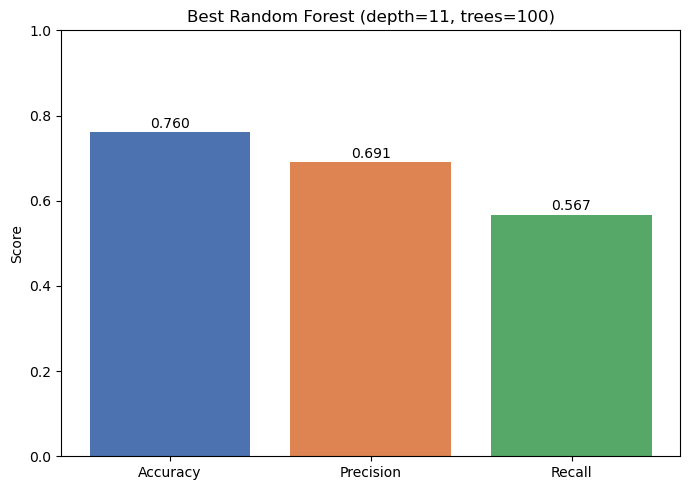

In [8]:
best_n = int(tree_results.loc[tree_results["Accuracy"].idxmax(), "n_estimators"])
best = RandomForestClassifier(n_estimators=best_n, max_depth=best_depth, random_state=42)
best.fit(X_train, y_train)
bp = best.predict(X_test)

scores = {
    "Accuracy":  accuracy_score(y_test, bp),
    "Precision": precision_score(y_test, bp),
    "Recall":    recall_score(y_test, bp),
}
print(f"Best model -> max_depth={best_depth}, n_estimators={best_n}")
print({k: round(v, 3) for k, v in scores.items()})

plt.figure(figsize=(7, 5))
bars = plt.bar(scores.keys(), scores.values(),
               color=["#4C72B0", "#DD8452", "#55A868"])
for b, v in zip(bars, scores.values()):
    plt.text(b.get_x() + b.get_width()/2, v + 0.01, f"{v:.3f}", ha="center")
plt.ylim(0, 1)
plt.ylabel("Score")
plt.title(f"Best Random Forest (depth={best_depth}, trees={best_n})")
plt.tight_layout()
plt.show()

### 6.1 Feature importance of the best model

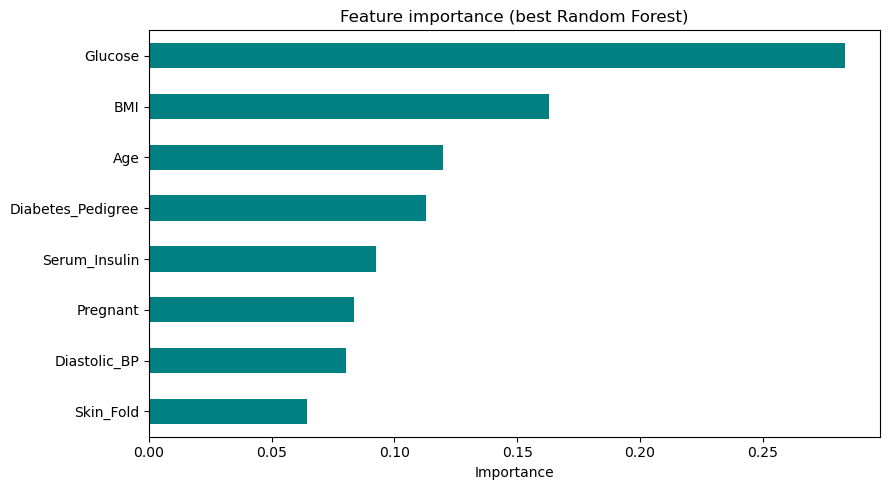

In [9]:
imp = pd.Series(best.feature_importances_, index=X.columns).sort_values()

plt.figure(figsize=(9, 5))
imp.plot(kind="barh", color="teal")
plt.xlabel("Importance")
plt.title("Feature importance (best Random Forest)")
plt.tight_layout()
plt.show()

## 7. Conclusion

* **Tree height:** accuracy rises quickly for the first few levels of depth, then flattens
  and can dip slightly as very deep trees start to overfit the training data.
* **Number of trees:** performance improves as trees are added and then stabilises - beyond a
  point extra trees cost compute without improving the scores.
* **Precision vs Recall:** on this imbalanced dataset (500 vs 268) precision is generally
  higher than recall, i.e. the model is more reliable when it predicts *diabetic* than it is
  at catching every diabetic case.
* The best configuration and its metrics are shown in section 6; `Glucose`, `BMI` and `Age`
  are usually the most important features.